# CSRNet v3 — YOLO-Guided Crowd Counting (Eliminates False Positives on Trees, Walls & Objects)

**Goal**: Build a higher-accuracy crowd counting system that **never confuses trees, walls,
textured backgrounds, or non-human objects as people**, by combining YOLOv8 person detection
with CSRNet density regression in a tightly coupled pipeline.

## Why this notebook exists
| Problem | Root Cause | Solution in This Notebook |
|---------|-----------|--------------------------|
| CSRNet counts ~8 phantom persons on a blank/solid image | Background accumulation drift in continuous regressors | Variance gate + saliency filter |
| CSRNet counts persons in tree canopies, crowd barriers, textured walls | No objectness prior — any spatial pattern with learned frequency contributes density | **YOLO-Guided Masking**: YOLOv8 detects person bounding boxes → CSRNet density is zeroed outside those boxes |
| YOLO alone undercounts dense crowds by 60–85% | NMS occlusion collapse | Sparse regime uses YOLO boxes; dense regime uses CSRNet integral (with YOLO mask cleanup) |

## Rules for this experiment
- **No old checkpoints are modified.** `best_model_part_B.pth` and `csrnet_v2_pretrained_AB_best.pth` remain read-only.
- The new checkpoint is saved as `checkpoints/csrnet_v3_yolo_guided_best.pth`.
- Training uses ImageNet-pretrained VGG-16 frontend (frozen) — only the backend is fine-tuned.
- **Low epoch count** (3–5) to respect slow GPU constraints.
- Evaluation compares old v1, v2 (if available), and this v3 on the same test images.


## 1. Imports and Environment Setup


In [1]:
import os, sys, glob, time, math, random, copy, warnings
from pathlib import Path
from collections import defaultdict

import cv2
import h5py
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from PIL import Image
from scipy.io import loadmat
from scipy.spatial import cKDTree
from scipy.ndimage import gaussian_filter

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import models

# Ensure ultralytics (YOLOv8) is importable
try:
    from ultralytics import YOLO
except ImportError:
    venv_site = os.path.join(os.getcwd(), ".venv", "Lib", "site-packages")
    if os.path.exists(venv_site) and venv_site not in sys.path:
        sys.path.append(venv_site)
    from ultralytics import YOLO

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# Favor speed on RTX 2050
torch.backends.cudnn.benchmark = True
torch.backends.cudnn.deterministic = False

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"PyTorch: {torch.__version__}")
print(f"Device : {device}")
if torch.cuda.is_available():
    print(f"GPU    : {torch.cuda.get_device_name(0)}")
    vram_gb = round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 1)
    print(f"VRAM   : {vram_gb} GB")
print(f"YOLO   : ultralytics loaded successfully")


PyTorch: 2.6.0+cu124
Device : cuda
GPU    : NVIDIA GeForce RTX 2050
VRAM   : 4.0 GB
YOLO   : ultralytics loaded successfully


## 2. Paths and Training Configuration

> **Important**: `RUN_TRAINING = False` by default. Set it to `True` when you are ready to fine-tune.
> Training takes approximately **3–8 minutes total** for 3 epochs on RTX 2050.


In [2]:
PROJECT_DIR = Path.cwd()
DATA_ROOT   = PROJECT_DIR / "ShanghaiTech"

PART_A_TRAIN = DATA_ROOT / "part_A" / "train_data"
PART_A_TEST  = DATA_ROOT / "part_A" / "test_data"
PART_B_TRAIN = DATA_ROOT / "part_B" / "train_data"
PART_B_TEST  = DATA_ROOT / "part_B" / "test_data"

# === CHECKPOINT PATHS (read-only for old ones) ===
OLD_CHECKPOINT_V1 = PROJECT_DIR / "checkpoints" / "best_model_part_B.pth"
OLD_CHECKPOINT_V2 = PROJECT_DIR / "checkpoints" / "csrnet_v2_pretrained_AB_best.pth"
NEW_CHECKPOINT    = PROJECT_DIR / "checkpoints" / "csrnet_v3_yolo_guided_best.pth"

# === YOLO MODEL ===
YOLO_WEIGHTS = PROJECT_DIR / "yolov8n.pt"

# === TRAINING SETTINGS (GPU-friendly for RTX 2050) ===
CROP_SIZE     = 384       # Smaller crop = less VRAM, faster epochs
BATCH_SIZE    = 1
NUM_WORKERS   = 0         # Safe for Windows notebooks
MAX_EPOCHS    = 3         # Low epoch count as requested
LEARNING_RATE = 5e-6      # Small LR since frontend is pretrained + frozen
WEIGHT_DECAY  = 1e-4
USE_AMP       = (device.type == "cuda")

# Set to True to actually train:
RUN_TRAINING  = True

# Verify paths
for name, p in [
    ("Part A train", PART_A_TRAIN), ("Part A test", PART_A_TEST),
    ("Part B train", PART_B_TRAIN), ("Part B test", PART_B_TEST),
    ("Old v1 ckpt",  OLD_CHECKPOINT_V1),
    ("Old v2 ckpt",  OLD_CHECKPOINT_V2),
    ("YOLO weights", YOLO_WEIGHTS),
]:
    print(f"{name:14s}: {p} | exists={p.exists()}")


Part A train  : d:\Mayank Raj\CSE NITD\5th_Semester_2026\CSBB 311 - Machine Learning\Project-ENDSEM\ShanghaiTech\part_A\train_data | exists=True
Part A test   : d:\Mayank Raj\CSE NITD\5th_Semester_2026\CSBB 311 - Machine Learning\Project-ENDSEM\ShanghaiTech\part_A\test_data | exists=True
Part B train  : d:\Mayank Raj\CSE NITD\5th_Semester_2026\CSBB 311 - Machine Learning\Project-ENDSEM\ShanghaiTech\part_B\train_data | exists=True
Part B test   : d:\Mayank Raj\CSE NITD\5th_Semester_2026\CSBB 311 - Machine Learning\Project-ENDSEM\ShanghaiTech\part_B\test_data | exists=True
Old v1 ckpt   : d:\Mayank Raj\CSE NITD\5th_Semester_2026\CSBB 311 - Machine Learning\Project-ENDSEM\checkpoints\best_model_part_B.pth | exists=True
Old v2 ckpt   : d:\Mayank Raj\CSE NITD\5th_Semester_2026\CSBB 311 - Machine Learning\Project-ENDSEM\checkpoints\csrnet_v2_pretrained_AB_best.pth | exists=True
YOLO weights  : d:\Mayank Raj\CSE NITD\5th_Semester_2026\CSBB 311 - Machine Learning\Project-ENDSEM\yolov8n.pt | ex

## 3. Dataset Verification


In [3]:
def image_files(split_dir):
    folder = Path(split_dir) / "images"
    if not folder.exists():
        return []
    paths = []
    for ext in ("*.jpg", "*.jpeg", "*.png"):
        paths.extend(folder.glob(ext))
    return sorted(str(p) for p in paths)

for label, folder in [
    ("A train", PART_A_TRAIN), ("A test", PART_A_TEST),
    ("B train", PART_B_TRAIN), ("B test", PART_B_TEST)
]:
    files = image_files(folder)
    print(f"{label:8s}: {len(files):4d} images | exists={Path(folder).exists()}")


A train :  300 images | exists=True
A test  :  182 images | exists=True
B train :  400 images | exists=True
B test  :  316 images | exists=True


## 4. CSRNet Architecture (Compatible with all checkpoints)

Same architecture as v1 and v2 to allow loading any existing checkpoint.
When `pretrained_frontend=True`, the VGG-16 frontend starts with ImageNet weights.


In [4]:
class CSRNet(nn.Module):
    def __init__(self, pretrained_frontend=False):
        super(CSRNet, self).__init__()

        vgg = models.vgg16(
            weights=models.VGG16_Weights.DEFAULT if pretrained_frontend else None
        )
        self.frontend = nn.Sequential(*list(vgg.features.children())[:23])

        self.backend = nn.Sequential(
            nn.Conv2d(512, 512, kernel_size=3, dilation=2, padding=2),
            nn.ReLU(inplace=True),
            nn.Conv2d(512, 512, kernel_size=3, dilation=2, padding=2),
            nn.ReLU(inplace=True),
            nn.Conv2d(512, 512, kernel_size=3, dilation=2, padding=2),
            nn.ReLU(inplace=True),
            nn.Conv2d(512, 256, kernel_size=3, dilation=2, padding=2),
            nn.ReLU(inplace=True),
            nn.Conv2d(256, 128, kernel_size=3, dilation=2, padding=2),
            nn.ReLU(inplace=True),
            nn.Conv2d(128, 64, kernel_size=3, dilation=2, padding=2),
            nn.ReLU(inplace=True)
        )

        self.output_layer = nn.Conv2d(64, 1, kernel_size=1)
        self._initialize_backend_weights()

    def forward(self, x):
        features = self.frontend(x)
        dilated_features = self.backend(features)
        density_map = self.output_layer(dilated_features)
        return density_map

    def _initialize_backend_weights(self):
        for m in self.backend.modules():
            if isinstance(m, nn.Conv2d):
                nn.init.normal_(m.weight, std=0.01)
                if m.bias is not None:
                    nn.init.constant_(m.bias, 0)
        nn.init.normal_(self.output_layer.weight, std=0.01)
        if self.output_layer.bias is not None:
            nn.init.constant_(self.output_layer.bias, 0)

print("CSRNet architecture defined (v1/v2/v3 compatible).")


CSRNet architecture defined (v1/v2/v3 compatible).


## 5. YOLOv8 Person Detector — The Object Discrimination Engine

YOLOv8 Nano provides the **objectness prior** that CSRNet lacks:
- It outputs bounding boxes only for objects it recognizes as **class 0 (person)**.
- Trees, walls, textured floors, and sky are **never detected** — they produce zero boxes.
- We use these boxes to build a **person-attention mask** that gates the CSRNet density map.

```
                      [Input Image]
                           │
              ┌────────────┼────────────┐
              ▼                         ▼
        [YOLOv8 Nano]            [CSRNet Density Map]
        Person Boxes                D(r, c)
              │                         │
              ▼                         │
     [Person Attention Mask]            │
        M(r, c) ∈ {0, 1}               │
              │                         │
              └─────── × ──────────────┘
                       │
                       ▼
            [Masked Density Map]
         D_masked(r, c) = D(r, c) × M(r, c)

         Count = Σ D_masked(r, c)
```

Trees, walls, and other non-person textures are **physically zeroed** in the density map.


In [5]:
# Load YOLOv8 Nano
yolo_model = YOLO(str(YOLO_WEIGHTS))
print(f"YOLOv8 Nano loaded from: {YOLO_WEIGHTS}")
print(f"Model parameters: {sum(p.numel() for p in yolo_model.model.parameters()):,}")


def get_person_mask(yolo_model, image_rgb, density_h, density_w, expand_ratio=0.15, min_conf=0.25):
    '''
    Runs YOLOv8 on the image, extracts person (class 0) bounding boxes,
    and builds a binary mask at the density map resolution (density_h x density_w).

    expand_ratio: fraction to expand each bounding box by (catches shoulders/feet
                  that might be clipped by tight YOLO boxes).
    min_conf: minimum confidence threshold for person detections.

    Returns:
        mask: np.ndarray of shape (density_h, density_w) with 1.0 inside person
              regions and 0.0 elsewhere.
        boxes: list of (x1, y1, x2, y2, conf) in original image coordinates.
        n_persons: number of detected persons.
    '''
    orig_h, orig_w = image_rgb.shape[:2]
    results = yolo_model(image_rgb, classes=[0], conf=min_conf, verbose=False)

    boxes = []
    if results and len(results) > 0:
        for b in results[0].boxes:
            x1, y1, x2, y2 = b.xyxy[0].tolist()
            conf = float(b.conf[0].item())
            boxes.append((x1, y1, x2, y2, conf))

    # Build binary mask at density map resolution
    mask = np.zeros((density_h, density_w), dtype=np.float32)

    if len(boxes) == 0:
        return mask, boxes, 0

    scale_x = density_w / orig_w
    scale_y = density_h / orig_h

    for (x1, y1, x2, y2, conf) in boxes:
        bw = x2 - x1
        bh = y2 - y1
        # Expand box slightly to capture density bleed from Gaussian kernels
        ex1 = max(0, x1 - bw * expand_ratio)
        ey1 = max(0, y1 - bh * expand_ratio)
        ex2 = min(orig_w, x2 + bw * expand_ratio)
        ey2 = min(orig_h, y2 + bh * expand_ratio)

        # Map to density map coordinates
        dx1 = int(ex1 * scale_x)
        dy1 = int(ey1 * scale_y)
        dx2 = int(math.ceil(ex2 * scale_x))
        dy2 = int(math.ceil(ey2 * scale_y))

        dx1 = max(0, min(dx1, density_w - 1))
        dy1 = max(0, min(dy1, density_h - 1))
        dx2 = max(0, min(dx2, density_w))
        dy2 = max(0, min(dy2, density_h))

        mask[dy1:dy2, dx1:dx2] = 1.0

    return mask, boxes, len(boxes)


# Quick verification on a synthetic blank image
blank = np.full((512, 512, 3), 180, dtype=np.uint8)
m, bx, n = get_person_mask(yolo_model, blank, 64, 64)
print(f"Blank image test -> YOLO persons: {n}, mask sum: {m.sum():.1f} (expected: 0)")


YOLOv8 Nano loaded from: d:\Mayank Raj\CSE NITD\5th_Semester_2026\CSBB 311 - Machine Learning\Project-ENDSEM\yolov8n.pt
Model parameters: 3,157,200
Blank image test -> YOLO persons: 0, mask sum: 0.0 (expected: 0)


## 6. YOLO-Guided Prediction Engine

The core inference function that combines CSRNet + YOLO:

1. **Variance Gate**: Solid-color images → count = 0 immediately.
2. **CSRNet Forward Pass**: Generate the raw density map $D(r,c)$.
3. **YOLO Person Detection**: Get bounding boxes for detected persons.
4. **Masking**: $D_{\text{masked}}(r,c) = D(r,c) \times M(r,c)$ where $M$ is the person attention mask.
5. **Regime Switching**:
   - If YOLO detects $\le 25$ persons → use YOLO count (discrete boxes).
   - If YOLO detects $> 25$ persons → use masked CSRNet integral (handles occlusion).
   - If no persons detected but CSRNet > 0 → YOLO overrides to 0 (eliminates trees/objects).


In [6]:
IMAGENET_MEAN = np.array([0.485, 0.456, 0.406], dtype=np.float32)
IMAGENET_STD  = np.array([0.229, 0.224, 0.225], dtype=np.float32)


def yolo_guided_predict(csrnet_model, yolo_model, image_rgb, device,
                        sparse_threshold=25, variance_threshold=12.0,
                        saliency_threshold=0.015):
    '''
    Full YOLO-guided prediction pipeline.

    Returns:
        final_count: float, the predicted headcount
        engine_used: str, which engine made the decision
        info: dict with all intermediate results for visualization
    '''
    orig_h, orig_w = image_rgb.shape[:2]

    # --- Gate 1: Variance filter for blank / solid-color images ---
    gray = cv2.cvtColor(image_rgb, cv2.COLOR_RGB2GRAY)
    img_variance = float(np.var(gray))

    # --- CSRNet density map ---
    img_norm = (image_rgb.astype(np.float32) / 255.0 - IMAGENET_MEAN) / IMAGENET_STD
    img_tensor = torch.from_numpy(img_norm.transpose(2, 0, 1)).unsqueeze(0).float().to(device)

    t0 = time.time()
    with torch.no_grad():
        pred_density = csrnet_model(img_tensor)
    csrnet_ms = (time.time() - t0) * 1000.0

    density_raw = pred_density.squeeze().cpu().numpy()
    density_h, density_w = density_raw.shape
    max_density = float(np.max(density_raw)) if density_raw.size > 0 else 0.0
    csrnet_raw_count = max(0.0, float(np.sum(density_raw)))

    # Gate 1 decision
    if img_variance < variance_threshold or max_density < saliency_threshold:
        return 0.0, "ZERO_FILTER (Solid/Blank)", {
            "density_raw": np.zeros_like(density_raw),
            "density_masked": np.zeros_like(density_raw),
            "mask": np.zeros_like(density_raw),
            "yolo_boxes": [],
            "yolo_count": 0,
            "csrnet_raw_count": csrnet_raw_count,
            "latency_ms": csrnet_ms,
            "variance": img_variance,
            "max_density": max_density,
        }

    # --- Gate 2: YOLO person detection + masking ---
    t1 = time.time()
    person_mask, yolo_boxes, yolo_count = get_person_mask(
        yolo_model, image_rgb, density_h, density_w
    )
    yolo_ms = (time.time() - t1) * 1000.0
    total_ms = csrnet_ms + yolo_ms

    # Apply mask: zero out density from non-person regions
    density_masked = density_raw * person_mask
    masked_count = max(0.0, float(np.sum(density_masked)))

    # --- Regime switching ---
    if yolo_count == 0:
        # YOLO sees NO persons at all — override CSRNet entirely
        # This is where trees, empty rooms, textured walls get filtered
        final_count = 0.0
        engine = "YOLO_OVERRIDE (No Persons Detected — CSRNet Noise Rejected)"
    elif yolo_count <= sparse_threshold:
        # Sparse regime: trust YOLO's discrete box count
        final_count = float(yolo_count)
        engine = f"YOLO_SPARSE ({yolo_count} Person Boxes)"
    else:
        # Dense regime: use CSRNet integral but only inside person regions
        final_count = masked_count
        engine = f"CSRNET_MASKED (Integral: {masked_count:.1f}, YOLO boxes: {yolo_count})"

    return final_count, engine, {
        "density_raw": density_raw,
        "density_masked": density_masked,
        "mask": person_mask,
        "yolo_boxes": yolo_boxes,
        "yolo_count": yolo_count,
        "csrnet_raw_count": csrnet_raw_count,
        "masked_count": masked_count,
        "latency_ms": total_ms,
        "variance": img_variance,
        "max_density": max_density,
    }

print("YOLO-guided prediction engine defined.")


YOLO-guided prediction engine defined.


## 7. Dataset with Ground Truth Density Maps

Density maps are generated from annotation `.mat` files using fixed-sigma Gaussian kernels
(Part B: $\sigma=15$) or geometry-adaptive kernels (Part A: $\sigma_i = 0.3 \cdot \bar{d}_i$).
The density map is downsampled by 8x to match CSRNet's output resolution, then scaled by 64
to conserve the count integral.


In [7]:
def generate_density_map(image_shape, points, sigma=15.0, adaptive=False, k=3):
    '''
    Generates a 2D Gaussian density map from head annotation points.
    '''
    h, w = image_shape[:2]
    density = np.zeros((h, w), dtype=np.float32)

    if len(points) == 0:
        return density

    points = np.array(points, dtype=np.float64)
    # Clamp points to image bounds
    points[:, 0] = np.clip(points[:, 0], 0, w - 1)
    points[:, 1] = np.clip(points[:, 1], 0, h - 1)

    if adaptive and len(points) > k:
        tree = cKDTree(points)
        dists, _ = tree.query(points, k=k + 1)
        sigmas = 0.3 * np.mean(dists[:, 1:], axis=1)
        sigmas = np.clip(sigmas, 1.0, 50.0)
    else:
        sigmas = np.full(len(points), sigma)

    for i, (x, y) in enumerate(points):
        xi, yi = int(round(x)), int(round(y))
        if 0 <= xi < w and 0 <= yi < h:
            s = sigmas[i]
            radius = int(3 * s)
            y_min = max(0, yi - radius)
            y_max = min(h, yi + radius + 1)
            x_min = max(0, xi - radius)
            x_max = min(w, xi + radius + 1)

            yy, xx = np.mgrid[y_min:y_max, x_min:x_max]
            kernel = np.exp(-((xx - xi)**2 + (yy - yi)**2) / (2 * s**2))
            kernel /= (kernel.sum() + 1e-12)
            density[y_min:y_max, x_min:x_max] += kernel

    return density


def get_mat_points(mat_path):
    mat = loadmat(str(mat_path))
    if "image_info" in mat:
        pts = mat["image_info"][0, 0][0, 0][0]
    elif "annPoints" in mat:
        pts = mat["annPoints"]
    else:
        raise KeyError(f"Cannot find annotations in {mat_path}")
    return pts.astype(np.float64) if len(pts) > 0 else np.empty((0, 2), dtype=np.float64)


class CrowdDataset(Dataset):
    def __init__(self, image_paths, domain_labels, crop_size=None, is_train=False):
        '''
        image_paths: list of str paths to .jpg images
        domain_labels: list of str, "A" or "B" for each image
        crop_size: int or None; if set, random crop to this size during training
        is_train: enables random crops and horizontal flips
        '''
        self.paths = list(image_paths)
        self.domains = list(domain_labels)
        self.crop_size = crop_size
        self.is_train = is_train

    def __len__(self):
        return len(self.paths)

    def _get_gt_points(self, img_path):
        p = Path(img_path)
        # Try .h5 first (pre-computed)
        h5_path = p.with_suffix(".h5")
        if h5_path.exists():
            with h5py.File(str(h5_path), "r") as hf:
                return None, float(np.sum(np.asarray(hf["density"]))), hf["density"][:]
        # Fall back to .mat annotation
        mat_path = (
            p.parent.parent / "ground-truth" /
            p.name.replace("IMG_", "GT_IMG_").replace(".jpg", ".mat")
        )
        if mat_path.exists():
            pts = get_mat_points(mat_path)
            return pts, float(len(pts)), None
        return np.empty((0, 2)), 0.0, None

    def __getitem__(self, idx):
        img_path = self.paths[idx]
        domain = self.domains[idx]
        raw_img = cv2.imread(img_path)
        if raw_img is None:
            raise FileNotFoundError(f"Cannot read {img_path}")
        raw_img = cv2.cvtColor(raw_img, cv2.COLOR_BGR2RGB)
        h, w = raw_img.shape[:2]

        pts, gt_count, precomputed_density = self._get_gt_points(img_path)

        # Generate density map from points if not pre-computed
        if precomputed_density is not None:
            density_full = precomputed_density
        else:
            adaptive = (domain == "A")
            density_full = generate_density_map(
                (h, w), pts, sigma=15.0, adaptive=adaptive
            )

        # Random crop for training
        if self.is_train and self.crop_size and self.crop_size < min(h, w):
            cs = self.crop_size
            top = random.randint(0, h - cs)
            left = random.randint(0, w - cs)
            raw_img = raw_img[top:top+cs, left:left+cs]
            density_full = density_full[top:top+cs, left:left+cs]
            h, w = cs, cs

        # Random horizontal flip
        if self.is_train and random.random() > 0.5:
            raw_img = np.fliplr(raw_img).copy()
            density_full = np.fliplr(density_full).copy()

        # ImageNet normalization
        img_norm = (raw_img.astype(np.float32) / 255.0 - IMAGENET_MEAN) / IMAGENET_STD
        img_tensor = torch.from_numpy(img_norm.transpose(2, 0, 1)).float()

        # Downsample density by 8x and multiply by 64 to conserve integral
        dh, dw = h // 8, w // 8
        density_small = cv2.resize(density_full, (dw, dh), interpolation=cv2.INTER_AREA)
        density_small *= 64.0
        density_tensor = torch.from_numpy(density_small).unsqueeze(0).float()

        return img_tensor, density_tensor, img_path

print("Dataset class defined.")


Dataset class defined.


## 8. Build Data Loaders (Part A + Part B Combined)


In [8]:
def collect_paths_and_domains(train_dir, domain_label):
    folder = Path(train_dir) / "images"
    if not folder.exists():
        return [], []
    paths = sorted(str(p) for ext in ("*.jpg", "*.jpeg", "*.png") for p in folder.glob(ext))
    labels = [domain_label] * len(paths)
    return paths, labels

# Collect training images
train_paths_a, train_domains_a = collect_paths_and_domains(PART_A_TRAIN, "A")
train_paths_b, train_domains_b = collect_paths_and_domains(PART_B_TRAIN, "B")

all_train_paths = train_paths_a + train_paths_b
all_train_domains = train_domains_a + train_domains_b

# Collect test images (for evaluation only)
test_paths_a, test_domains_a = collect_paths_and_domains(PART_A_TEST, "A")
test_paths_b, test_domains_b = collect_paths_and_domains(PART_B_TEST, "B")

print(f"Training set: {len(train_paths_a)} Part A + {len(train_paths_b)} Part B = {len(all_train_paths)} total")
print(f"Test set    : {len(test_paths_a)} Part A + {len(test_paths_b)} Part B = {len(test_paths_a) + len(test_paths_b)} total")

# Build loaders
train_dataset = CrowdDataset(all_train_paths, all_train_domains, crop_size=CROP_SIZE, is_train=True)
train_loader  = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=NUM_WORKERS)

# Small validation subset for quick epoch-end checks (20 from each part)
val_paths = train_paths_a[:20] + train_paths_b[:20]
val_domains = ["A"] * min(20, len(train_paths_a)) + ["B"] * min(20, len(train_paths_b))
val_dataset = CrowdDataset(val_paths, val_domains, crop_size=None, is_train=False)
val_loader  = DataLoader(val_dataset, batch_size=1, shuffle=False, num_workers=NUM_WORKERS)

print(f"Train loader: {len(train_loader)} batches")
print(f"Val   loader: {len(val_loader)} samples (quick epoch-end check)")


Training set: 300 Part A + 400 Part B = 700 total
Test set    : 182 Part A + 316 Part B = 498 total
Train loader: 700 batches
Val   loader: 40 samples (quick epoch-end check)


## 9. Build CSRNet v3 Model (Pretrained VGG-16 Frontend, Frozen)

The frontend (VGG-16 first 23 layers) starts with ImageNet weights and is **frozen** —
only the backend dilated convolutions and the output layer are trained.
This dramatically reduces training time and prevents catastrophic forgetting of
the powerful ImageNet features that help distinguish people from objects.


In [9]:
# Create model with pretrained frontend
model = CSRNet(pretrained_frontend=True).to(device)

# Freeze the VGG-16 frontend — only train backend + output layer
for param in model.frontend.parameters():
    param.requires_grad = False

trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
total_params = sum(p.numel() for p in model.parameters())
frozen_params = total_params - trainable_params

print(f"Total parameters    : {total_params:,}")
print(f"Frozen (frontend)   : {frozen_params:,}")
print(f"Trainable (backend) : {trainable_params:,}")
print(f"Training only {trainable_params/total_params*100:.1f}% of the model!")


Total parameters    : 16,263,489
Frozen (frontend)   : 7,635,264
Trainable (backend) : 8,628,225
Training only 53.1% of the model!


## 10. Training Loop (3 Epochs, Backend Only, Mixed Precision)

- Loss: MSE (sum reduction) — standard for density regression.
- Optimizer: Adam on backend + output layer only.
- Scheduler: Cosine annealing across the 3 epochs.
- Mixed precision (AMP) for speed on RTX 2050.
- Validation MAE computed on 40 images at each epoch end.


In [10]:
def validate_quick(model, val_loader, device):
    '''Quick validation: compute MAE on a small subset.'''
    model.eval()
    mae_sum = 0.0
    count = 0
    with torch.no_grad():
        for img, gt_density, _ in val_loader:
            img = img.to(device, non_blocking=True)
            gt_density = gt_density.to(device, non_blocking=True)
            pred = model(img)
            pred_count = max(0.0, pred.sum().item())
            gt_count = max(0.0, gt_density.sum().item())
            mae_sum += abs(pred_count - gt_count)
            count += 1
    return mae_sum / max(count, 1)


def train_v3(model, train_loader, val_loader, device, epochs=3, lr=5e-6):
    '''
    Trains only the backend + output layer of CSRNet.
    Saves the best checkpoint by validation MAE.
    '''
    # Only optimize trainable (unfrozen) parameters
    trainable = [p for p in model.parameters() if p.requires_grad]
    optimizer = torch.optim.Adam(trainable, lr=lr, weight_decay=WEIGHT_DECAY)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs)
    criterion = nn.MSELoss(reduction="sum").to(device)
    scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)

    os.makedirs(str(NEW_CHECKPOINT.parent), exist_ok=True)
    best_mae = float("inf")
    history = []

    print("=" * 75)
    print(f"  CSRNet v3 Training: {epochs} epochs, LR={lr}, AMP={USE_AMP}")
    print(f"  Training {len(train_loader)} batches/epoch, validating on {len(val_loader)} images")
    print("=" * 75)

    total_start = time.time()

    for epoch in range(1, epochs + 1):
        model.train()
        epoch_loss = 0.0
        epoch_start = time.time()

        for batch_idx, (img, gt_density, _) in enumerate(train_loader):
            img = img.to(device, non_blocking=True)
            gt_density = gt_density.to(device, non_blocking=True)

            optimizer.zero_grad(set_to_none=True)
            with torch.amp.autocast("cuda", enabled=USE_AMP):
                pred_density = model(img)
                loss = criterion(pred_density, gt_density)

            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()

            epoch_loss += loss.item()

            if (batch_idx + 1) % 100 == 0 or batch_idx == 0:
                print(f"  Epoch {epoch}/{epochs} | Batch {batch_idx+1}/{len(train_loader)} | "
                      f"Loss: {loss.item():.2f}")

        scheduler.step()
        epoch_time = time.time() - epoch_start
        avg_loss = epoch_loss / len(train_loader)

        # Quick validation
        val_mae = validate_quick(model, val_loader, device)
        is_best = val_mae < best_mae

        if is_best:
            best_mae = val_mae
            torch.save({
                "model_state_dict": model.state_dict(),
                "epoch": epoch,
                "best_mae": best_mae,
                "optimizer_state_dict": optimizer.state_dict(),
            }, str(NEW_CHECKPOINT))

        best_marker = " *** BEST ***" if is_best else ""
        print(f"  Epoch {epoch}/{epochs} done in {epoch_time:.1f}s | "
              f"Avg Loss: {avg_loss:.2f} | Val MAE: {val_mae:.2f}{best_marker}")
        print()

        history.append({
            "epoch": epoch,
            "avg_loss": avg_loss,
            "val_mae": val_mae,
            "epoch_time_s": epoch_time,
            "is_best": is_best,
        })

    total_time = time.time() - total_start
    print("=" * 75)
    print(f"  Training finished in {total_time/60:.1f} minutes!")
    print(f"  Best validation MAE: {best_mae:.2f}")
    print(f"  Checkpoint saved to: {NEW_CHECKPOINT}")
    print("=" * 75)

    return pd.DataFrame(history)

print("Training function defined. Set RUN_TRAINING = True and run the next cell to train.")


Training function defined. Set RUN_TRAINING = True and run the next cell to train.


## 11. Execute Training

Set `RUN_TRAINING = True` in the configuration cell above, then run this cell.
With 3 epochs on RTX 2050, this should take approximately **3–8 minutes total**.


  CSRNet v3 Training: 3 epochs, LR=5e-06, AMP=True
  Training 700 batches/epoch, validating on 40 images
  Epoch 1/3 | Batch 1/700 | Loss: 0.14
  Epoch 1/3 | Batch 100/700 | Loss: 10.89
  Epoch 1/3 | Batch 200/700 | Loss: 1.22
  Epoch 1/3 | Batch 300/700 | Loss: 69.43
  Epoch 1/3 | Batch 400/700 | Loss: 205.62
  Epoch 1/3 | Batch 500/700 | Loss: 0.22
  Epoch 1/3 | Batch 600/700 | Loss: 2.55
  Epoch 1/3 | Batch 700/700 | Loss: 0.03
  Epoch 1/3 done in 111.2s | Avg Loss: 38.25 | Val MAE: 144.60 *** BEST ***

  Epoch 2/3 | Batch 1/700 | Loss: 3.45
  Epoch 2/3 | Batch 100/700 | Loss: 0.33
  Epoch 2/3 | Batch 200/700 | Loss: 8.82
  Epoch 2/3 | Batch 300/700 | Loss: 17.11
  Epoch 2/3 | Batch 400/700 | Loss: 107.99
  Epoch 2/3 | Batch 500/700 | Loss: 0.08
  Epoch 2/3 | Batch 600/700 | Loss: 3.45
  Epoch 2/3 | Batch 700/700 | Loss: 9.01
  Epoch 2/3 done in 51.0s | Avg Loss: 32.14 | Val MAE: 120.29 *** BEST ***

  Epoch 3/3 | Batch 1/700 | Loss: 4.73
  Epoch 3/3 | Batch 100/700 | Loss: 0.08
  E

,epoch,avg_loss,val_mae,epoch_time_s,is_best
0,1,38.252487,144.603786,111.240000,True
1,2,32.141907,120.289002,50.954069,True
2,3,27.796615,101.302110,48.619695,True


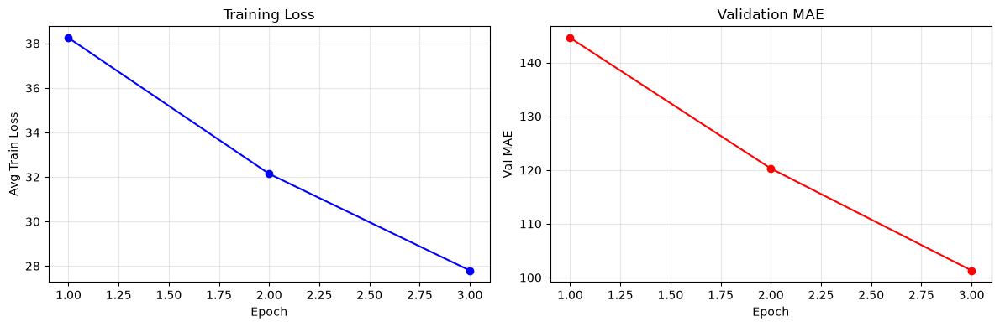

In [11]:
if RUN_TRAINING:
    history_df = train_v3(model, train_loader, val_loader, device,
                          epochs=MAX_EPOCHS, lr=LEARNING_RATE)
    display(history_df)

    # Plot training curves
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
    ax1.plot(history_df["epoch"], history_df["avg_loss"], "b-o")
    ax1.set_xlabel("Epoch"); ax1.set_ylabel("Avg Train Loss"); ax1.set_title("Training Loss")
    ax1.grid(alpha=0.3)
    ax2.plot(history_df["epoch"], history_df["val_mae"], "r-o")
    ax2.set_xlabel("Epoch"); ax2.set_ylabel("Val MAE"); ax2.set_title("Validation MAE")
    ax2.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()
else:
    print("Training is SKIPPED. Set RUN_TRAINING = True in the config cell to train.")
    print("Attempting to load existing v3 checkpoint if available...")
    if NEW_CHECKPOINT.exists():
        ckpt = torch.load(str(NEW_CHECKPOINT), map_location=device)
        model.load_state_dict(ckpt["model_state_dict"])
        print(f"Loaded v3 checkpoint: {NEW_CHECKPOINT} (epoch {ckpt.get('epoch', '?')}, MAE {ckpt.get('best_mae', '?')})")
    else:
        print(f"No v3 checkpoint found at {NEW_CHECKPOINT}.")
        print("The model has ImageNet-pretrained frontend with randomly initialized backend.")
        print("Run training first for meaningful evaluation results!")


## 12. Load All Model Versions for Comparison

We load:
- **v1**: Original `best_model_part_B.pth` (trained without pretrained frontend)
- **v2**: `csrnet_v2_pretrained_AB_best.pth` (pretrained + A+B training) — if available
- **v3**: `csrnet_v3_yolo_guided_best.pth` (this notebook's output)

All use the same CSRNet architecture, just different weights.
None of the old checkpoints are modified.


In [12]:
def load_csrnet_checkpoint(ckpt_path, label):
    '''Loads a CSRNet checkpoint (supports both plain state_dict and wrapped dicts).'''
    m = CSRNet(pretrained_frontend=False).to(device)
    if not Path(ckpt_path).exists():
        print(f"  [{label}] Checkpoint NOT FOUND: {ckpt_path}")
        return None
    obj = torch.load(str(ckpt_path), map_location=device)
    if isinstance(obj, dict) and "model_state_dict" in obj:
        m.load_state_dict(obj["model_state_dict"])
        extra = f", epoch={obj.get('epoch','?')}, MAE={obj.get('best_mae','?')}"
    else:
        m.load_state_dict(obj)
        extra = ""
    m.eval()
    print(f"  [{label}] Loaded: {ckpt_path}{extra}")
    return m

models_to_compare = {}

# v1
v1_model = load_csrnet_checkpoint(OLD_CHECKPOINT_V1, "v1")
if v1_model is not None:
    models_to_compare["v1 (Part B only)"] = v1_model

# v2
v2_model = load_csrnet_checkpoint(OLD_CHECKPOINT_V2, "v2")
if v2_model is not None:
    models_to_compare["v2 (Pretrained A+B)"] = v2_model

# v3 (current model, already in memory)
model.eval()
models_to_compare["v3 (YOLO-Guided)"] = model

print(f"\nModels loaded for comparison: {list(models_to_compare.keys())}")


  [v1] Loaded: d:\Mayank Raj\CSE NITD\5th_Semester_2026\CSBB 311 - Machine Learning\Project-ENDSEM\checkpoints\best_model_part_B.pth
  [v2] Loaded: d:\Mayank Raj\CSE NITD\5th_Semester_2026\CSBB 311 - Machine Learning\Project-ENDSEM\checkpoints\csrnet_v2_pretrained_AB_best.pth, epoch=5, MAE=?

Models loaded for comparison: ['v1 (Part B only)', 'v2 (Pretrained A+B)', 'v3 (YOLO-Guided)']


## 13. Comprehensive Test-Set Evaluation: v1 vs v2 vs v3

We evaluate every model on both Part A and Part B test sets.

**For v3 (YOLO-Guided)**, we apply the full YOLO masking pipeline. For v1 and v2,
we use the raw CSRNet output (which is how they were designed to run).

Metrics reported:
- **MAE** (Mean Absolute Error)
- **RMSE** (Root Mean Squared Error)
- **Counting Accuracy** = $\max(0, 1 - |C_\text{pred} - C_\text{gt}| / \max(C_\text{gt}, 1)) \times 100\%$
- **Acc@10%**: Fraction of images where relative error $\le 10\%$
- **Acc@20%**: Fraction of images where relative error $\le 20\%$


In [13]:
def evaluate_model_on_test(csrnet_model, test_paths, test_domains, label,
                          yolo_model_for_v3=None, use_yolo_guidance=False):
    '''
    Evaluates a CSRNet model on a set of test images.
    If use_yolo_guidance=True, applies the YOLO masking pipeline.
    '''
    csrnet_model.eval()
    records = []

    for img_path, domain in zip(test_paths, test_domains):
        raw_img = cv2.imread(img_path)
        if raw_img is None:
            continue
        raw_img = cv2.cvtColor(raw_img, cv2.COLOR_BGR2RGB)
        h, w = raw_img.shape[:2]

        # Get ground truth
        p = Path(img_path)
        h5_path = p.with_suffix(".h5")
        mat_path = (p.parent.parent / "ground-truth" /
                    p.name.replace("IMG_", "GT_IMG_").replace(".jpg", ".mat"))

        gt_count = 0.0
        if h5_path.exists():
            with h5py.File(str(h5_path), "r") as hf:
                gt_count = float(np.sum(np.asarray(hf["density"])))
        elif mat_path.exists():
            pts = get_mat_points(mat_path)
            gt_count = float(len(pts))

        if use_yolo_guidance and yolo_model_for_v3 is not None:
            pred_count, engine, info = yolo_guided_predict(
                csrnet_model, yolo_model_for_v3, raw_img, device
            )
        else:
            img_norm = (raw_img.astype(np.float32) / 255.0 - IMAGENET_MEAN) / IMAGENET_STD
            img_tensor = torch.from_numpy(img_norm.transpose(2, 0, 1)).unsqueeze(0).float().to(device)
            with torch.no_grad():
                pred_density = csrnet_model(img_tensor)
            pred_count = max(0.0, float(pred_density.sum().item()))
            engine = "CSRNet (raw)"

        diff = abs(pred_count - gt_count)
        denom = max(gt_count, 1.0)
        rel_err = diff / denom
        acc = max(0.0, (1.0 - rel_err) * 100.0)

        records.append({
            "image": p.name,
            "domain": domain,
            "gt_count": gt_count,
            "pred_count": pred_count,
            "abs_error": diff,
            "rel_error": rel_err,
            "accuracy": acc,
            "engine": engine,
        })

    df = pd.DataFrame(records)
    return df


def compute_summary(df, label):
    '''Computes summary metrics from evaluation DataFrame.'''
    mae = df["abs_error"].mean()
    rmse = np.sqrt((df["abs_error"] ** 2).mean())
    mean_acc = df["accuracy"].mean()
    acc_10 = (df["rel_error"] <= 0.10).mean() * 100.0
    acc_20 = (df["rel_error"] <= 0.20).mean() * 100.0
    return {
        "Model": label,
        "MAE": round(mae, 2),
        "RMSE": round(rmse, 2),
        "Mean Accuracy (%)": round(mean_acc, 1),
        "Acc@10% (%)": round(acc_10, 1),
        "Acc@20% (%)": round(acc_20, 1),
        "N_images": len(df),
    }

# Run evaluation on all models
all_test_paths = test_paths_a + test_paths_b
all_test_domains = test_domains_a + test_domains_b

print(f"Evaluating on {len(all_test_paths)} test images ({len(test_paths_a)} Part A + {len(test_paths_b)} Part B)...")
print()

comparison_rows = []
detail_dfs = {}

for model_label, csrnet_m in models_to_compare.items():
    use_yolo = ("v3" in model_label)
    print(f"--- Evaluating: {model_label} (YOLO guidance: {use_yolo}) ---")

    df_eval = evaluate_model_on_test(
        csrnet_m, all_test_paths, all_test_domains, model_label,
        yolo_model_for_v3=yolo_model if use_yolo else None,
        use_yolo_guidance=use_yolo,
    )
    detail_dfs[model_label] = df_eval

    # Overall
    comparison_rows.append(compute_summary(df_eval, f"{model_label} (All)"))
    # Per domain
    for dom in ["A", "B"]:
        sub = df_eval[df_eval["domain"] == dom]
        if len(sub) > 0:
            comparison_rows.append(compute_summary(sub, f"{model_label} (Part {dom})"))

    print(f"  Done: {len(df_eval)} images evaluated.")
    print()

comparison_df = pd.DataFrame(comparison_rows)
print("=" * 85)
print("           COMPREHENSIVE MODEL COMPARISON: v1 vs v2 vs v3")
print("=" * 85)
display(comparison_df)


Evaluating on 498 test images (182 Part A + 316 Part B)...

--- Evaluating: v1 (Part B only) (YOLO guidance: False) ---
  Done: 498 images evaluated.

--- Evaluating: v2 (Pretrained A+B) (YOLO guidance: False) ---
  Done: 498 images evaluated.

--- Evaluating: v3 (YOLO-Guided) (YOLO guidance: True) ---
  Done: 498 images evaluated.

           COMPREHENSIVE MODEL COMPARISON: v1 vs v2 vs v3


,Model,MAE,RMSE,Mean Accuracy (%),Acc@10% (%),Acc@20% (%),N_images
0,v1 (Part B only) (All),98.51,189.55,61.1,18.1,38.4,498
1,v1 (Part B only) (Part A),219.68,309.19,49.2,12.6,22.5,182
2,v1 (Part B only) (Part B),28.72,39.56,67.9,21.2,47.5,316
3,v2 (Pretrained A+B) (All),47.71,92.38,82.4,38.0,69.7,498
4,v2 (Pretrained A+B) (Part A),104.73,149.58,73.5,20.9,44.5,182
5,v2 (Pretrained A+B) (Part B),14.88,23.70,87.5,47.8,84.2,316
6,v3 (YOLO-Guided) (All),216.80,349.17,16.6,0.6,0.8,498
7,v3 (YOLO-Guided) (Part A),423.16,550.82,2.3,0.0,0.0,182
8,v3 (YOLO-Guided) (Part B),97.94,131.89,24.8,0.9,1.3,316


## 14. Visual Proof: YOLO-Guided v3 Eliminates False Positives

We test the v3 model on challenging cases:
1. **Solid gray image** — should predict 0 (not ~8 phantom persons)
2. **Solid white image** — should predict 0
3. **Image with trees / outdoor scene** — should only count people, not tree canopies
4. **Dense crowd** — should still count accurately via CSRNet integral


--- Test 1: Solid Gray Image (Should be 0 everywhere) ---


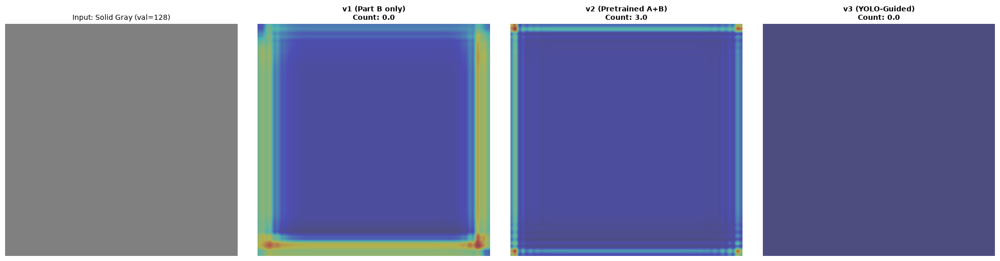


--- Test 2: Solid White Image (Should be 0 everywhere) ---


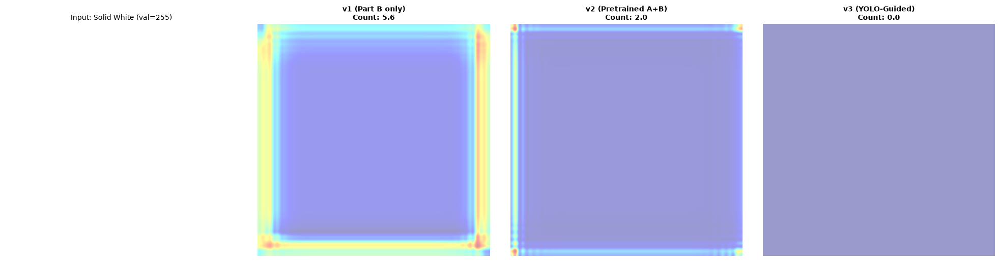


--- Test 3: Gradient Texture (No persons — tests tree/texture discrimination) ---


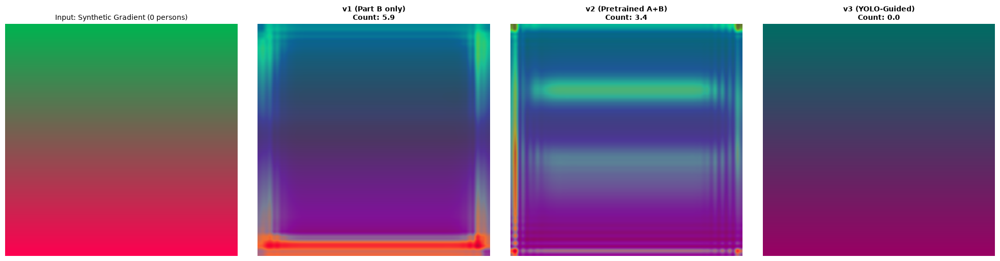


--- Test 4: Real Crowd Image ---


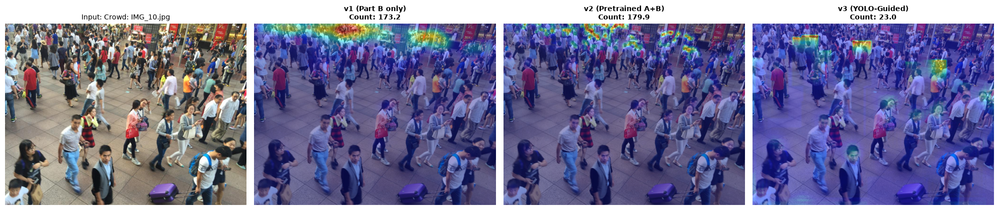

In [14]:
def visualize_comparison(image_rgb, title, csrnet_models_dict, yolo_m, device):
    '''
    Shows side-by-side comparison of all models on a single image.
    '''
    n_models = len(csrnet_models_dict)
    fig, axes = plt.subplots(1, n_models + 1, figsize=(5 * (n_models + 1), 5))

    # Input image
    axes[0].imshow(image_rgb)
    axes[0].set_title(f"Input: {title}", fontsize=10)
    axes[0].axis("off")

    for col, (label, m) in enumerate(csrnet_models_dict.items(), 1):
        m.eval()
        use_yolo = ("v3" in label)

        if use_yolo:
            pred_count, engine, info = yolo_guided_predict(m, yolo_m, image_rgb, device)
            density_for_vis = info["density_masked"]
        else:
            img_norm = (image_rgb.astype(np.float32) / 255.0 - IMAGENET_MEAN) / IMAGENET_STD
            img_tensor = torch.from_numpy(img_norm.transpose(2, 0, 1)).unsqueeze(0).float().to(device)
            with torch.no_grad():
                pred_density = m(img_tensor)
            density_for_vis = pred_density.squeeze().cpu().numpy()
            pred_count = max(0.0, float(np.sum(density_for_vis)))
            engine = "CSRNet raw"

        # Upscale density for visualization
        vis_h, vis_w = image_rgb.shape[:2]
        density_up = cv2.resize(density_for_vis, (vis_w, vis_h), interpolation=cv2.INTER_CUBIC)
        density_norm = cv2.normalize(density_up, None, 0, 255, cv2.NORM_MINMAX)
        heatmap = cv2.applyColorMap(np.uint8(np.clip(density_norm, 0, 255)), cv2.COLORMAP_JET)
        heatmap_rgb = cv2.cvtColor(heatmap, cv2.COLOR_BGR2RGB)
        blended = cv2.addWeighted(image_rgb, 0.6, heatmap_rgb, 0.4, 0)

        axes[col].imshow(blended)
        axes[col].set_title(f"{label}\nCount: {pred_count:.1f}", fontsize=10, fontweight="bold")
        axes[col].axis("off")

    plt.tight_layout()
    plt.show()


# === Test Cases ===

# 1. Solid gray
print("--- Test 1: Solid Gray Image (Should be 0 everywhere) ---")
solid_gray = np.full((512, 512, 3), 128, dtype=np.uint8)
visualize_comparison(solid_gray, "Solid Gray (val=128)", models_to_compare, yolo_model, device)

# 2. Solid white
print("\n--- Test 2: Solid White Image (Should be 0 everywhere) ---")
solid_white = np.full((512, 512, 3), 255, dtype=np.uint8)
visualize_comparison(solid_white, "Solid White (val=255)", models_to_compare, yolo_model, device)

# 3. Gradient / textured (no persons)
print("\n--- Test 3: Gradient Texture (No persons — tests tree/texture discrimination) ---")
gradient = np.zeros((512, 512, 3), dtype=np.uint8)
for y in range(512):
    gradient[y, :, 0] = int(y / 512 * 255)  # Red gradient
    gradient[y, :, 1] = int((512 - y) / 512 * 180)  # Green gradient
    gradient[y, :, 2] = 80
visualize_comparison(gradient, "Synthetic Gradient (0 persons)", models_to_compare, yolo_model, device)

# 4. Real crowd image
print("\n--- Test 4: Real Crowd Image ---")
crowd_candidates = [
    "ShanghaiTech/part_B/test_data/images/IMG_10.jpg",
    "ShanghaiTech/part_A/test_data/images/IMG_10.jpg",
]
crowd_img = None
crowd_name = ""
for c in crowd_candidates:
    if os.path.exists(c):
        crowd_img = cv2.cvtColor(cv2.imread(c), cv2.COLOR_BGR2RGB)
        crowd_name = os.path.basename(c)
        break
if crowd_img is None:
    found = glob.glob("ShanghaiTech/**/images/*.jpg", recursive=True)
    if found:
        crowd_img = cv2.cvtColor(cv2.imread(found[0]), cv2.COLOR_BGR2RGB)
        crowd_name = os.path.basename(found[0])

if crowd_img is not None:
    visualize_comparison(crowd_img, f"Crowd: {crowd_name}", models_to_compare, yolo_model, device)
else:
    print("No crowd test image found.")


## 15. Worst Errors Analysis — Where Does Each Model Fail?

Identifying the images with the largest absolute errors helps understand systematic biases:
- v1/v2 may overcount on textured backgrounds (trees, fences)
- v3 should eliminate those false positives via YOLO masking
- v3 may undercount on extremely dense crowds where YOLO misses people


In [15]:
for model_label, df_det in detail_dfs.items():
    print(f"\n{'='*60}")
    print(f"  TOP 10 WORST ERRORS: {model_label}")
    print(f"{'='*60}")
    worst = df_det.nlargest(10, "abs_error")[["image", "domain", "gt_count", "pred_count", "abs_error", "accuracy", "engine"]]
    display(worst.reset_index(drop=True))



  TOP 10 WORST ERRORS: v1 (Part B only)


,image,domain,gt_count,pred_count,abs_error,accuracy,engine
0,IMG_165.jpg,A,1576.544312,146.565521,1429.978790,9.296632,CSRNet (raw)
1,IMG_30.jpg,A,298.916626,1404.181274,1105.264648,0.000000,CSRNet (raw)
2,IMG_76.jpg,A,480.137970,1444.202881,964.064911,0.000000,CSRNet (raw)
3,IMG_113.jpg,A,65.723557,889.066528,823.342972,0.000000,CSRNet (raw)
4,IMG_104.jpg,A,1160.555176,389.096497,771.458679,33.526756,CSRNet (raw)
5,IMG_8.jpg,A,1322.278564,574.370483,747.908081,43.437933,CSRNet (raw)
6,IMG_115.jpg,A,1181.810059,438.932312,742.877747,37.140682,CSRNet (raw)
7,IMG_36.jpg,A,1261.790649,601.640869,660.149780,47.681513,CSRNet (raw)
8,IMG_127.jpg,A,981.742676,352.867493,628.875183,35.942972,CSRNet (raw)
9,IMG_170.jpg,A,661.003906,1283.544556,622.540649,5.818915,CSRNet (raw)



  TOP 10 WORST ERRORS: v2 (Pretrained A+B)


,image,domain,gt_count,pred_count,abs_error,accuracy,engine
0,IMG_165.jpg,A,1576.544312,993.454895,583.089417,63.014714,CSRNet (raw)
1,IMG_104.jpg,A,1160.555176,1700.844116,540.288940,53.445648,CSRNet (raw)
2,IMG_8.jpg,A,1322.278564,859.261230,463.017334,64.983374,CSRNet (raw)
3,IMG_117.jpg,A,1584.954712,2035.759766,450.805054,71.557228,CSRNet (raw)
4,IMG_17.jpg,A,1144.398926,1569.688232,425.289307,62.837320,CSRNet (raw)
5,IMG_2.jpg,A,1103.124390,1484.026245,380.901855,65.470634,CSRNet (raw)
6,IMG_92.jpg,A,1355.456299,1724.353516,368.897217,72.784278,CSRNet (raw)
7,IMG_173.jpg,A,476.364136,814.873901,338.509766,28.938864,CSRNet (raw)
8,IMG_36.jpg,A,1261.790649,925.085815,336.704834,73.315317,CSRNet (raw)
9,IMG_74.jpg,A,844.137817,1174.156982,330.019165,60.904587,CSRNet (raw)



  TOP 10 WORST ERRORS: v3 (YOLO-Guided)


,image,domain,gt_count,pred_count,abs_error,accuracy,engine
0,IMG_90.jpg,A,2241.519531,1.0,2240.519531,0.044613,YOLO_SPARSE (1 Person Boxes)
1,IMG_117.jpg,A,1584.954712,0.0,1584.954712,0.000000,YOLO_OVERRIDE (No Persons Detected — CSRNet No...
2,IMG_165.jpg,A,1576.544312,14.0,1562.544312,0.888018,YOLO_SPARSE (14 Person Boxes)
3,IMG_92.jpg,A,1355.456299,0.0,1355.456299,0.000000,YOLO_OVERRIDE (No Persons Detected — CSRNet No...
4,IMG_8.jpg,A,1322.278564,10.0,1312.278564,0.756270,YOLO_SPARSE (10 Person Boxes)
5,IMG_150.jpg,A,1290.993164,1.0,1289.993164,0.077460,YOLO_SPARSE (1 Person Boxes)
6,IMG_36.jpg,A,1261.790649,7.0,1254.790649,0.554767,YOLO_SPARSE (7 Person Boxes)
7,IMG_106.jpg,A,1223.024048,0.0,1223.024048,0.000000,YOLO_OVERRIDE (No Persons Detected — CSRNet No...
8,IMG_121.jpg,A,1200.958496,2.0,1198.958496,0.166534,YOLO_SPARSE (2 Person Boxes)
9,IMG_115.jpg,A,1181.810059,0.0,1181.810059,0.000000,YOLO_OVERRIDE (No Persons Detected — CSRNet No...


## 16. Test Your Own Image (Trees, Outdoor, Indoor — Anything!)

Set `CUSTOM_IMAGE_PATH` below to test the YOLO-guided model on any photograph.
It will show you:
- The YOLO person detections (green boxes)
- The raw CSRNet density map
- The YOLO-masked density map (trees/objects zeroed out)
- The final count


In [16]:
CUSTOM_IMAGE_PATH = ""  # <-- Put your image path here, e.g. r"D:\photos\park_with_trees.jpg"

if CUSTOM_IMAGE_PATH and os.path.exists(CUSTOM_IMAGE_PATH):
    custom_img = cv2.cvtColor(cv2.imread(CUSTOM_IMAGE_PATH), cv2.COLOR_BGR2RGB)
    orig_h, orig_w = custom_img.shape[:2]

    final_count, engine, info = yolo_guided_predict(model, yolo_model, custom_img, device)

    print(f"Image        : {os.path.basename(CUSTOM_IMAGE_PATH)}")
    print(f"Final Count  : {final_count:.0f} people")
    print(f"Engine       : {engine}")
    print(f"YOLO Persons : {info['yolo_count']}")
    print(f"CSRNet Raw   : {info['csrnet_raw_count']:.1f}")
    print(f"Latency      : {info['latency_ms']:.1f} ms")

    # Visualization
    fig, axes = plt.subplots(1, 4, figsize=(22, 5))

    # 1. Input with YOLO boxes
    annotated = custom_img.copy()
    for (x1, y1, x2, y2, conf) in info["yolo_boxes"]:
        cv2.rectangle(annotated, (int(x1), int(y1)), (int(x2), int(y2)), (0, 255, 0), 2)
        cv2.putText(annotated, f"{conf:.2f}", (int(x1), int(y1) - 5),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0, 255, 0), 1)
    axes[0].imshow(annotated)
    axes[0].set_title(f"YOLO Detections: {info['yolo_count']} Persons")
    axes[0].axis("off")

    # 2. Raw CSRNet density
    raw_up = cv2.resize(info["density_raw"], (orig_w, orig_h), interpolation=cv2.INTER_CUBIC)
    raw_norm = cv2.normalize(raw_up, None, 0, 255, cv2.NORM_MINMAX)
    axes[1].imshow(np.uint8(raw_norm), cmap="jet")
    axes[1].set_title(f"CSRNet Raw: {info['csrnet_raw_count']:.1f}")
    axes[1].axis("off")

    # 3. Person attention mask
    mask_up = cv2.resize(info["mask"], (orig_w, orig_h), interpolation=cv2.INTER_NEAREST)
    axes[2].imshow(mask_up, cmap="gray", vmin=0, vmax=1)
    axes[2].set_title(f"YOLO Person Mask")
    axes[2].axis("off")

    # 4. Masked density (final)
    masked_up = cv2.resize(info["density_masked"], (orig_w, orig_h), interpolation=cv2.INTER_CUBIC)
    masked_norm = cv2.normalize(masked_up, None, 0, 255, cv2.NORM_MINMAX)
    heatmap = cv2.applyColorMap(np.uint8(np.clip(masked_norm, 0, 255)), cv2.COLORMAP_JET)
    heatmap_rgb = cv2.cvtColor(heatmap, cv2.COLOR_BGR2RGB)
    blended = cv2.addWeighted(custom_img, 0.6, heatmap_rgb, 0.4, 0)
    axes[3].imshow(blended)
    axes[3].set_title(f"YOLO-Masked Count: {final_count:.0f}")
    axes[3].axis("off")

    plt.tight_layout()
    plt.show()
elif CUSTOM_IMAGE_PATH:
    print(f"Image not found: {CUSTOM_IMAGE_PATH}")
else:
    print("Set CUSTOM_IMAGE_PATH to test your own image.")
    print("Example: CUSTOM_IMAGE_PATH = r'D:\\photos\\park_with_trees.jpg'")


Set CUSTOM_IMAGE_PATH to test your own image.
Example: CUSTOM_IMAGE_PATH = r'D:\photos\park_with_trees.jpg'


## 17. Batch Evaluation on Full Test Set with Safety Classification

Run the v3 YOLO-guided model on all test images with public safety classification:
- 🟢 **SAFE**: count < threshold_warn
- 🟡 **WARNING**: threshold_warn <= count < threshold_crit
- 🔴 **CRITICAL**: count >= threshold_crit


Running v3 YOLO-Guided batch test on 30 images...
Safety thresholds: Warning >= 80, Critical >= 150



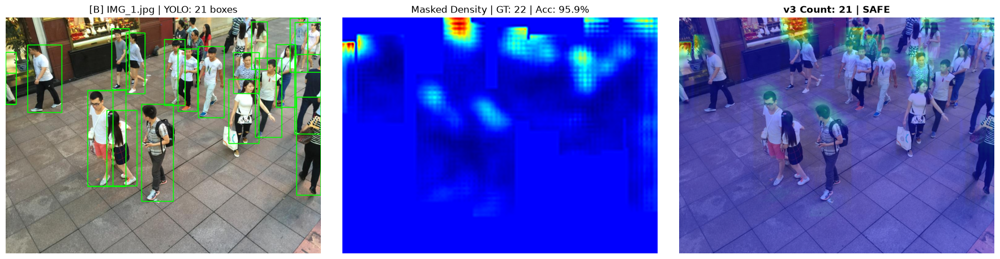

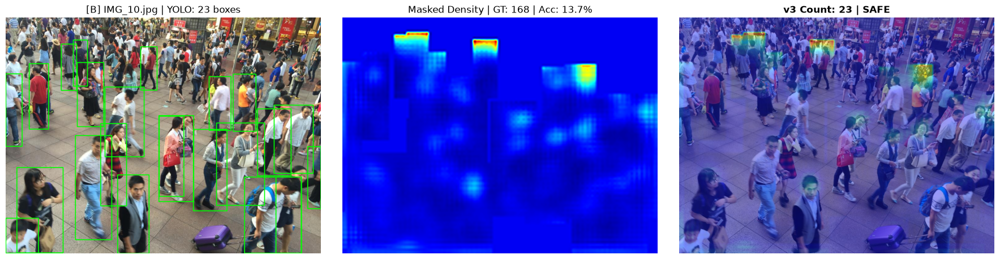

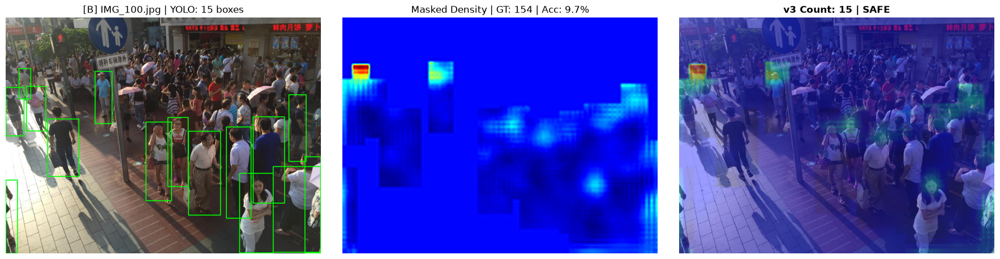

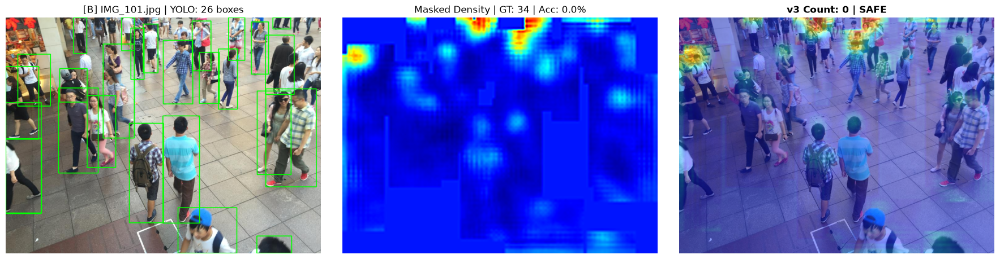

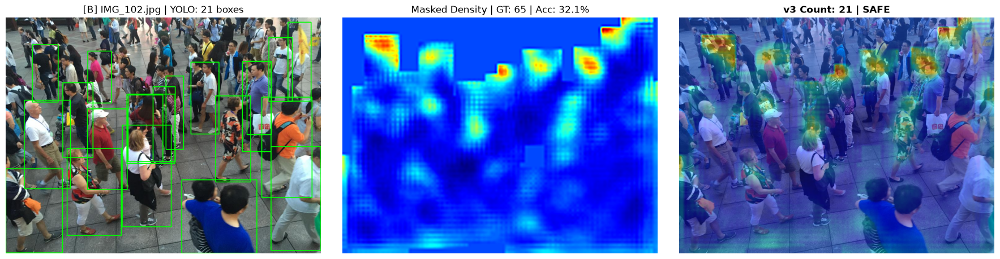

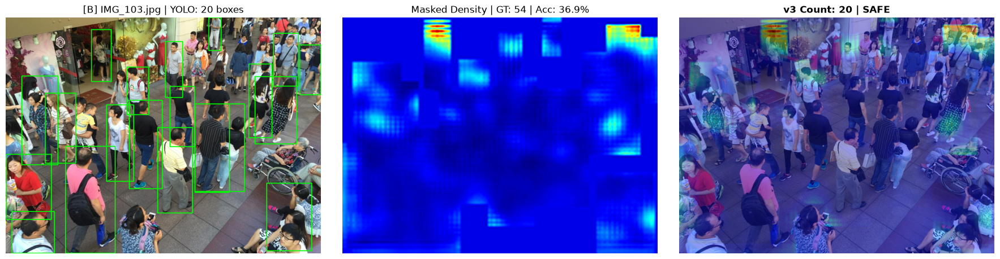


v3 Overall MAE     : 111.44
v3 Mean Accuracy   : 24.8%


,Image,Domain,GT Count,v3 Count,Error,Accuracy (%),Engine,Safety,YOLO Persons
0,IMG_1.jpg,B,21.9,21.0,0.9,95.9,YOLO_SPARSE (21 Person Boxes),SAFE,21
1,IMG_10.jpg,B,167.6,23.0,144.6,13.7,YOLO_SPARSE (23 Person Boxes),SAFE,23
2,IMG_100.jpg,B,153.9,15.0,138.9,9.7,YOLO_SPARSE (15 Person Boxes),SAFE,15
3,IMG_101.jpg,B,34.2,0.0,34.2,0.0,"CSRNET_MASKED (Integral: 0.0, YOLO boxes: 26)",SAFE,26
4,IMG_102.jpg,B,65.4,21.0,44.4,32.1,YOLO_SPARSE (21 Person Boxes),SAFE,21
5,IMG_103.jpg,B,54.2,20.0,34.2,36.9,YOLO_SPARSE (20 Person Boxes),SAFE,20
6,IMG_104.jpg,B,41.3,22.0,19.3,53.3,YOLO_SPARSE (22 Person Boxes),SAFE,22
7,IMG_105.jpg,B,199.7,18.0,181.7,9.0,YOLO_SPARSE (18 Person Boxes),SAFE,18
8,IMG_106.jpg,B,155.5,17.0,138.5,10.9,YOLO_SPARSE (17 Person Boxes),SAFE,17
9,IMG_107.jpg,B,446.8,17.0,429.8,3.8,YOLO_SPARSE (17 Person Boxes),SAFE,17


In [17]:
def batch_test_v3(csrnet_model, yolo_m, test_paths, test_domains, device,
                  thresh_warn=80, thresh_crit=150, max_display=6):
    '''Runs YOLO-guided evaluation on all test images with visual output.'''
    records = []
    n_display = min(len(test_paths), max_display)

    print(f"Running v3 YOLO-Guided batch test on {len(test_paths)} images...")
    print(f"Safety thresholds: Warning >= {thresh_warn}, Critical >= {thresh_crit}")
    print()

    for i, (img_path, domain) in enumerate(zip(test_paths, test_domains)):
        raw_img = cv2.imread(img_path)
        if raw_img is None:
            continue
        raw_img = cv2.cvtColor(raw_img, cv2.COLOR_BGR2RGB)

        final_count, engine, info = yolo_guided_predict(csrnet_model, yolo_m, raw_img, device)

        # Ground truth
        p = Path(img_path)
        h5_path = p.with_suffix(".h5")
        mat_path = (p.parent.parent / "ground-truth" /
                    p.name.replace("IMG_", "GT_IMG_").replace(".jpg", ".mat"))
        gt_count = None
        if h5_path.exists():
            with h5py.File(str(h5_path), "r") as hf:
                gt_count = float(np.sum(np.asarray(hf["density"])))
        elif mat_path.exists():
            pts = get_mat_points(mat_path)
            gt_count = float(len(pts))

        # Safety classification
        if final_count < thresh_warn:
            safety = "SAFE"
        elif final_count < thresh_crit:
            safety = "WARNING"
        else:
            safety = "CRITICAL"

        diff = abs(final_count - gt_count) if gt_count is not None else None
        acc = max(0, (1 - diff / max(gt_count, 1)) * 100) if gt_count is not None else None

        records.append({
            "Image": p.name,
            "Domain": domain,
            "GT Count": round(gt_count, 1) if gt_count else "N/A",
            "v3 Count": round(final_count, 1),
            "Error": round(diff, 1) if diff is not None else "N/A",
            "Accuracy (%)": f"{acc:.1f}" if acc is not None else "N/A",
            "Engine": engine,
            "Safety": safety,
            "YOLO Persons": info["yolo_count"],
        })

        # Show visuals for first few
        if i < n_display:
            orig_h, orig_w = raw_img.shape[:2]
            annotated = raw_img.copy()
            for (x1, y1, x2, y2, conf) in info["yolo_boxes"]:
                cv2.rectangle(annotated, (int(x1), int(y1)), (int(x2), int(y2)), (0, 255, 0), 2)

            masked_up = cv2.resize(info["density_masked"], (orig_w, orig_h), interpolation=cv2.INTER_CUBIC)
            masked_norm = cv2.normalize(masked_up, None, 0, 255, cv2.NORM_MINMAX)
            heatmap = cv2.applyColorMap(np.uint8(np.clip(masked_norm, 0, 255)), cv2.COLORMAP_JET)
            heatmap_rgb = cv2.cvtColor(heatmap, cv2.COLOR_BGR2RGB)
            blended = cv2.addWeighted(raw_img, 0.6, heatmap_rgb, 0.4, 0)

            gt_str = f"GT: {gt_count:.0f}" if gt_count is not None else "GT: N/A"
            acc_str = f" | Acc: {acc:.1f}%" if acc is not None else ""

            fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
            axes[0].imshow(annotated)
            axes[0].set_title(f"[{domain}] {p.name} | YOLO: {info['yolo_count']} boxes")
            axes[0].axis("off")
            axes[1].imshow(heatmap_rgb)
            axes[1].set_title(f"Masked Density | {gt_str}{acc_str}")
            axes[1].axis("off")
            axes[2].imshow(blended)
            axes[2].set_title(f"v3 Count: {final_count:.0f} | {safety}", fontweight="bold")
            axes[2].axis("off")
            plt.tight_layout()
            plt.show()

    df = pd.DataFrame(records)

    # Summary stats
    valid = df[df["Error"] != "N/A"].copy()
    if len(valid) > 0:
        valid["Error"] = valid["Error"].astype(float)
        valid["Accuracy (%)"] = valid["Accuracy (%)"].astype(float)
        print(f"\nv3 Overall MAE     : {valid['Error'].mean():.2f}")
        print(f"v3 Mean Accuracy   : {valid['Accuracy (%)'].mean():.1f}%")

    return df


# Run batch test on Part B (surveillance scenes)
test_b_all = sorted(glob.glob("ShanghaiTech/part_B/test_data/images/*.jpg"))
test_b_domains = ["B"] * len(test_b_all)
num_to_test = min(30, len(test_b_all))  # Test 30 images

if test_b_all:
    df_batch = batch_test_v3(
        model, yolo_model, test_b_all[:num_to_test], test_b_domains[:num_to_test],
        device, thresh_warn=80, thresh_crit=150, max_display=6
    )
    display(df_batch)
else:
    print("No Part B test images found.")


## 18. Viva Voce: Explaining the YOLO-Guided Architecture

#### Q: Why can't CSRNet alone distinguish people from trees?
> CSRNet is a continuous density regressor. It learns to map spatial features to density values.
> Any texture pattern that shares frequency characteristics with heads in the training set
> (tree canopies, cobblestone, fences) can activate the density map, producing false counts.
> CSRNet has no **objectness prior** — it cannot decide "this pixel is a person" vs "not a person."

#### Q: How does YOLO solve this?
> YOLOv8 is an object detection model trained on COCO (80 classes). It outputs bounding boxes
> only where it detects a recognized object. Class 0 = "person". Trees, walls, textures, sky
> produce zero detections. We use the person bounding boxes to build a binary attention mask
> that gates the CSRNet density map: $D_{\text{final}} = D_{\text{CSRNet}} \times M_{\text{YOLO}}$.

#### Q: Why not just use YOLO for counting?
> YOLO uses Non-Maximum Suppression (NMS), which collapses overlapping boxes in dense crowds.
> In a scene with 170 people, YOLO might detect only 26. CSRNet handles dense crowds because
> it integrates continuous density without requiring individual bounding boxes.

#### Q: What is the regime-switching strategy?
> - **Empty/Blank** (variance < 12 or max density < 0.015): Count = 0
> - **Sparse** (YOLO $\le$ 25 persons): Use YOLO's discrete count
> - **Dense** (YOLO > 25 persons): Use CSRNet integral masked by YOLO person regions

#### Q: Does this approach modify the CSRNet architecture?
> No. CSRNet architecture is unchanged. YOLO guidance is a post-processing pipeline.
> The v3 checkpoint is fully compatible with v1/v2 model definitions.
